# Community Detection - Aves Wildbird Network (AWN)

## Preprocessing

In [1]:
from WSSNMTF import *  # Relevant functions for WSSNMTF are defined here. 
# This was developed based on the algorithm introduced in the paper at: https://ieeexplore.ieee.org/abstract/document/7899821

# import other packages
import pandas as pd
import time
import community.community_louvain as community_louvain

In [2]:
# read data
df = pd.read_csv("aves-wildbird-network/aves-wildbird-network.txt", delimiter=' ', header=None)
df.columns = ['source','target','weight','day']
df.head()

,source,target,weight,day
0,1,2,0.013889,1
1,1,3,0.045455,1
2,1,4,0.038462,1
3,1,5,0.041237,1
4,1,6,0.039474,1


In [4]:
# Initialize empty adjacency matrices
adj_matrices = []

# Create a list of all unique nodes
all_nodes = sorted(set(df['source']) | set(df['target']))
num_nodes = len(all_nodes)
nodes_mapping = {node: i for i, node in enumerate(all_nodes)}

# Define the shape of the adjacency matrices
shape = (202, 202)

# Group DataFrame by 'day' column
grouped = df.groupby('day')

# Iterate over groups
for day, group in grouped:
    # Create empty adjacency matrix
    A = np.zeros(shape)
    
    # Aggregate weights for each unique pair of nodes
    for _, row in group.iterrows():
        source = nodes_mapping[row['source']]
        target = nodes_mapping[row['target']]
        weight = row['weight']
        A[source, target] += weight
        A[target, source] += weight  # Ensure symmetry
    
    # Add adjacency matrix to the list
    adj_matrices.append(A)

# Resulting adjacency matrices
for i, A in enumerate(adj_matrices, start=1):
    print(f"Adjacency Matrix for Day {i}:")
    print(A)
    print()

Adjacency Matrix for Day 1:
[[0.         0.01388889 0.04545455 ... 0.         0.         0.        ]
 [0.01388889 0.         0.         ... 0.         0.         0.        ]
 [0.04545455 0.         0.         ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]

Adjacency Matrix for Day 2:
[[0.         0.11570248 0.         ... 0.         0.         0.        ]
 [0.11570248 0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]

Adjacency Matrix for Day 3:
[[0. 0. 0. ... 0. 0. 0.]
 

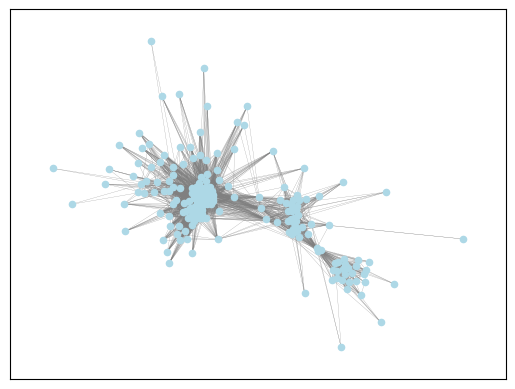

In [7]:
# Visualization: 6 layers combined
A = np.zeros((202, 202)) 
# Add adjacency matrices to A for each iteration
for i in range(6):
    A += adj_matrices[i]
    
G = nx.from_numpy_array(A)
degrees = dict(G.degree())
nx.draw_networkx(G, with_labels=False, node_size=20, node_color='lightblue', edge_color='grey', width=0.15)

## Testing Multilayer Community Detection

In [12]:
def labels_to_partition(labels):
    '''
    This function gives partition results in a list of sets based on label assignment
    An example usage is given below
    Input: a list of labels
    Output: a list of sets giving the partition results of the nodes
    '''
    partition = {}
    for node, community in enumerate(labels):
        if community not in partition:
            partition[community] = set()
        partition[community].add(node)
    return list(partition.values())

# example usage:
labels = [2, 2, 1, 0, 1]
partition = labels_to_partition(labels)
print(partition) 

[{0, 1}, {2, 4}, {3}]


In [29]:
# initialize a list to record modularity scores of each partition
modularities = []

In [30]:
# test the algorithm for k=2
print("Implementing...")
A_dict = {i: adj_matrices[i] for i in range(6)}
k = 2 # number of communities
tol = 1e-2

t0 = time.time() # start time
H,S = WSSNMTF(A_dict, k, tol)
t1 = time.time() # stop time

label_pred = actual_assignment(H)
partition = labels_to_partition(label_pred)
mod = nx.community.modularity(G, partition)
modularities.append(mod)
print(mod)
print('Elapsed time: %.2fs' % (t1-t0))

Implementing...
0.2724528113874862
Elapsed time: 0.33s


In [31]:
# test the algorithm for k=3
print("Implementing...")
A_dict = {i: adj_matrices[i] for i in range(6)}
k = 3 # number of communities
tol = 1e-2

t0 = time.time() # start time
H,S = WSSNMTF(A_dict, k, tol)
t1 = time.time() # stop time

label_pred = actual_assignment(H)
partition = labels_to_partition(label_pred)
mod = nx.community.modularity(G, partition)
modularities.append(mod)
print(mod)
print('Elapsed time: %.2fs' % (t1-t0))

Implementing...
0.24442776359572058
Elapsed time: 0.42s


In [32]:
# test the algorithm for k=4
print("Implementing...")
A_dict = {i: adj_matrices[i] for i in range(6)}
k = 4 # number of communities
tol = 1e-2

t0 = time.time() # start time
H,S = WSSNMTF(A_dict, k, tol)
t1 = time.time() # stop time

label_pred = actual_assignment(H)
partition = labels_to_partition(label_pred)
mod = nx.community.modularity(G, partition)
modularities.append(mod)
print(mod)
print('Elapsed time: %.2fs' % (t1-t0))

Implementing...
0.21426349796600674
Elapsed time: 0.53s


In [33]:
# test the algorithm for k=5
print("Implementing...")
A_dict = {i: adj_matrices[i] for i in range(6)}
k = 5 # number of communities
tol = 1e-2

t0 = time.time() # start time
H,S = WSSNMTF(A_dict, k, tol)
t1 = time.time() # stop time

label_pred = actual_assignment(H)
partition = labels_to_partition(label_pred)
mod = nx.community.modularity(G, partition)
modularities.append(mod)
print(mod)
print('Elapsed time: %.2fs' % (t1-t0))

Implementing...
0.189868934592438
Elapsed time: 1.56s


In [34]:
# test the algorithm for k=6
print("Implementing...")
A_dict = {i: adj_matrices[i] for i in range(6)}
k = 6 # number of communities
tol = 1e-2

t0 = time.time() # start time
H,S = WSSNMTF(A_dict, k, tol)
t1 = time.time() # stop time

label_pred = actual_assignment(H)
partition = labels_to_partition(label_pred)
mod = nx.community.modularity(G, partition)
modularities.append(mod)
print(mod)
print('Elapsed time: %.2fs' % (t1-t0))

Implementing...
0.19714797630133346
Elapsed time: 25.03s


In [35]:
# test the algorithm for k=7
print("Implementing...")
A_dict = {i: adj_matrices[i] for i in range(6)}
k = 7 # number of communities
tol = 1e-2

t0 = time.time() # start time
H,S = WSSNMTF(A_dict, k, tol)
t1 = time.time() # stop time

label_pred = actual_assignment(H)
partition = labels_to_partition(label_pred)
mod = nx.community.modularity(G, partition)
modularities.append(mod)
print(mod)
print('Elapsed time: %.2fs' % (t1-t0))

Implementing...
0.2178744345763481
Elapsed time: 2.94s


In [38]:
# test the algorithm for k=8
print("Implementing...")
A_dict = {i: adj_matrices[i] for i in range(6)}
k = 8 # number of communities
tol = 1e-2

t0 = time.time() # start time
H,S = WSSNMTF(A_dict, k, tol)
t1 = time.time() # stop time

label_pred = actual_assignment(H)
partition = labels_to_partition(label_pred)
mod = nx.community.modularity(G, partition)
modularities.append(mod)
print(mod)
print('Elapsed time: %.2fs' % (t1-t0))

Implementing...
0.1837231485433163
Elapsed time: 517.19s


Time complexity has significantly increased, so we have to stop here. So far, the tested choices of parameter for the number of communities (2~8) has sufficiently covered a range in which we are interested. 

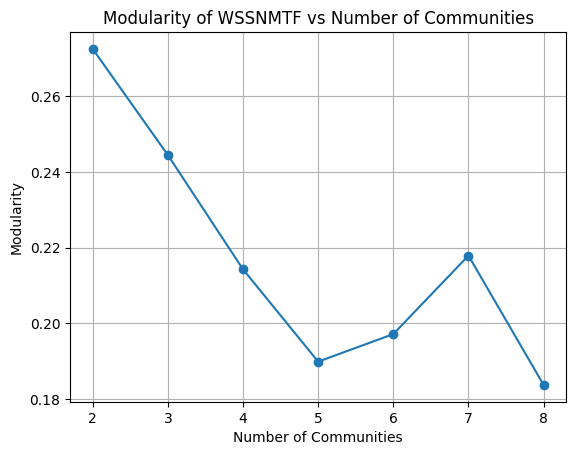

In [39]:
# Plotting modularity vs number of communities
num_communities_range = [2,3,4,5,6,7,8]
plt.plot(num_communities_range, modularities, marker='o')
plt.title('Modularity of WSSNMTF vs Number of Communities')
plt.xlabel('Number of Communities')
plt.ylabel('Modularity')
plt.grid(True)
plt.show()

In [37]:
A_new = {i: new_adjacency(adj_matrices[i], 5, 0.1) for i in range(6)}

In [38]:
# Testing
print("Implementing...")
k = 3 # number of communities
tol = 1e-5

t0 = time.time() # start time
H,S = WSSNMTF(A_new, k, tol)
t1 = time.time() # stop time

print(H)
print("Completed")
print('Elapsed time: %.2fs' % (t1-t0))

Implementing...
[[2.62119246e-003 3.51781010e-003 1.43192108e-002]
 [1.26450140e-002 6.13857442e-003 1.49687764e-002]
 [2.57207475e-105 1.44483331e-005 2.41817698e-003]
 [8.78769625e-004 4.38234469e-003 8.22536646e-003]
 [4.75263221e-003 4.69255080e-003 1.53792938e-002]
 [1.21533337e-002 7.10157048e-003 1.63239251e-002]
 [9.89254678e-003 4.74182249e-003 9.19655486e-003]
 [1.10188973e+000 2.47032823e-323 3.50107766e-002]
 [1.25000827e-002 6.18518907e-003 1.20017636e-002]
 [1.32040402e-002 5.87372720e-003 1.57630444e-002]
 [5.73199926e-003 4.61004260e-003 1.29147874e-002]
 [5.24155179e-003 4.74434032e-003 1.08888601e-002]
 [1.27127260e-003 2.40015710e-003 6.07747567e-003]
 [5.26531772e-003 3.24516268e-003 1.30346975e-002]
 [1.32635328e-002 5.60660589e-003 1.37886516e-002]
 [5.93255992e-003 2.09974244e-003 8.99047638e-003]
 [2.45703943e-003 8.92923836e-004 6.81506400e-003]
 [5.46658826e-003 2.37968501e-004 1.17183283e-002]
 [4.68604161e-003 2.18790083e-003 1.27294372e-002]
 [6.58343557e-0

In [39]:
label_pred = actual_assignment(H)
print(silhouette_score(M,label_pred))
print(calinski_harabasz_score(M,label_pred))
print(davies_bouldin_score(M,label_pred))

-0.18309260947145592
4.335395776846153
5.458645377361537


In [41]:
label_pred

array([2, 2, 2, 2, 2, 2, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       0, 2, 2, 2, 0, 2, 2, 0, 1, 2, 1, 2, 2, 1, 2, 0, 0, 2, 2, 0, 2, 2,
       2, 2, 1, 2, 0, 0, 0, 2, 1, 0, 2, 2, 1, 2, 0, 0, 2, 0, 1, 0, 1, 1,
       2, 1, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2, 2, 2, 0, 2, 2, 2, 0, 2, 0, 2,
       2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 0, 2, 1, 1, 2, 0, 1, 0, 2, 1,
       1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 2, 0, 0, 0, 0, 1, 1, 0, 2,
       2, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2, 2, 2, 1, 1, 0, 2, 2, 0, 0, 2, 2,
       2, 1, 2, 2, 1, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 2, 1, 2, 1,
       1, 2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2])

In [47]:
partition = labels_to_partition(label_pred)
print(partition)

[{0, 1, 2, 3, 4, 5, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 23, 24, 25, 27, 28, 31, 33, 34, 36, 39, 40, 42, 43, 44, 45, 47, 51, 54, 55, 57, 60, 66, 68, 69, 71, 72, 73, 75, 76, 77, 78, 79, 81, 82, 83, 85, 87, 88, 89, 90, 91, 92, 93, 94, 96, 97, 98, 99, 101, 104, 108, 123, 131, 132, 133, 134, 135, 136, 139, 140, 141, 142, 143, 144, 148, 149, 152, 153, 154, 156, 157, 159, 161, 162, 163, 164, 165, 166, 167, 168, 171, 172, 174, 177, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201}, {130, 6, 7, 8, 147, 22, 150, 151, 26, 29, 37, 38, 41, 48, 49, 50, 53, 58, 59, 61, 63, 70, 74, 80, 84, 86, 100, 105, 107, 111, 112, 114, 117, 122, 124, 125, 126, 127}, {128, 129, 137, 138, 145, 146, 155, 30, 158, 32, 160, 35, 169, 170, 173, 46, 175, 176, 178, 179, 52, 56, 62, 64, 65, 67, 95, 102, 103, 106, 109, 110, 113, 115, 116, 118, 119, 120, 121}]


In [48]:
nx.community.modularity(G, partition)

0.02547559826061632

In [55]:
# Testing
print("Implementing...")
'''M = np.zeros((202, 202)) 
# Add adjacency matrices to A for each iteration
for i in range(6):
    M += adj_matrices[i]'''
A = {0: adj_matrices[0]+adj_matrices[1], 
     1: adj_matrices[2]+adj_matrices[3], 
     2: adj_matrices[4]+adj_matrices[5]}
k = 3 # number of communities
tol = 1e-5

t0 = time.time() # start time
H,S = WSSNMTF(A, k, tol)
t1 = time.time() # stop time

print(H)
print("Completed")
print('Elapsed time: %.2fs' % (t1-t0))

Implementing...
[[5.34813740e-003 6.47953205e-003 1.24804816e-001]
 [2.17388884e-322 1.94516590e-225 8.63209813e-001]
 [6.16286419e-002 2.79625020e-003 1.25028719e-002]
 [2.94600290e-001 1.13635099e-322 3.28139120e-001]
 [6.21642193e-002 3.60200935e+000 3.16707190e-001]
 [4.03387578e-003 2.91809812e-002 9.81404945e-001]
 [2.25855360e-002 2.73189429e-003 6.37466077e-001]
 [6.00791679e-003 3.87004151e-001 5.36410352e-002]
 [9.58652884e-002 3.99128755e-002 6.61471581e-001]
 [8.89318163e-323 9.38724727e-323 9.25850238e-001]
 [1.99852499e+000 2.09396798e-001 1.37936776e-001]
 [1.98570089e+000 2.43198376e-001 8.53718164e-002]
 [2.25641835e-002 2.25314269e+000 1.43048683e-001]
 [9.71212710e-169 1.72922976e-322 5.28014293e-001]
 [1.82804289e-322 2.76676762e-322 9.01828044e-001]
 [8.55628364e-003 3.27183830e-002 9.79220588e-001]
 [2.53768084e-002 8.89318163e-323 2.18021086e-001]
 [2.20518963e-002 1.11786561e+000 1.19965366e-001]
 [1.02172966e-002 4.27650796e-001 7.86151392e-001]
 [1.31763380e-1

In [56]:
label_pred = actual_assignment(H)
print(silhouette_score(M,label_pred))
print(calinski_harabasz_score(M,label_pred))
print(davies_bouldin_score(M,label_pred))

0.02448452647289386
19.676118821751015
2.437685654659554


In [57]:
partition = labels_to_partition(label_pred)
nx.community.modularity(G, partition)

0.3113103169289921

## Experimenting the Built-In Single Layer Methods

In [40]:
def assign_labels(partition, num_nodes):
    '''
    This function assigns labels to the nodes in a partition result
    input: partition result and number of nodes in the partition
    output: an array of labels
    '''
    labels_pred = [-1] * num_nodes  # Initialize labels with -1

    for label, nodes in enumerate(partition):
        for node in nodes:
            labels_pred[node] = label

    return labels_pred

### Louvain
We want to get a preliminary view of the clustering results. We first used Louvain, which gives the best partition by evaluating the modularity. 

In [42]:
def louvain(A):
    G = nx.from_numpy_array(A)
    # Generate the partition using the Louvain algorithm
    partition = community_louvain.best_partition(G)
    
    # Convert the partition into a format suitable for nx.modularity
    # The modularity function expects a list of sets of nodes
    community_dict = {}
    for node, community in partition.items():
        if community not in community_dict:
            community_dict[community] = []
        community_dict[community].append(node)
    communities = list(community_dict.values())
    
    # Compute the modularity
    modularity = nx.algorithms.community.quality.modularity(G, communities)
    
    # Count the number of unique communities
    num_communities = len(set(partition.values()))
    
    return modularity, num_communities

modularity, num_communities = louvain(A)

print(f"Modularity: {modularity}")
print(f"Number of communities: {num_communities}")

Modularity: 0.5274821354227012
Number of communities: 6


We can now briefly look at the time evolution of modularity in the 6 days using Louvain. At each day we use only nodes that have previously appeared to more accurately simulate the real world scenario.

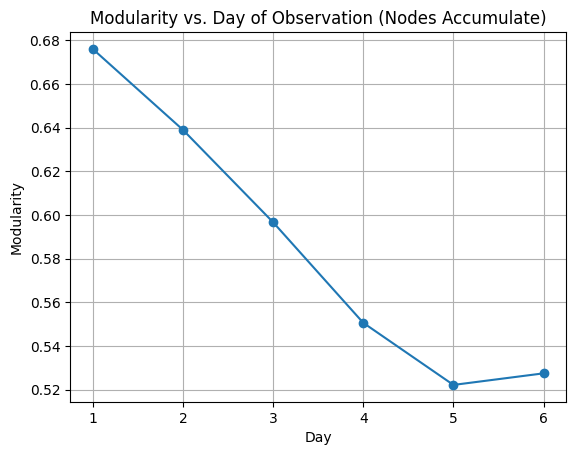

In [62]:
def remove_isolated_nodes(adj_matrix):
    # Find isolated nodes (nodes with no connections)
    isolated_nodes = np.where(np.sum(adj_matrix, axis=1) == 0)[0]

    # Remove isolated nodes and their corresponding rows/columns
    new_matrix = np.delete(adj_matrix, isolated_nodes, axis=0)
    new_matrix = np.delete(new_matrix, isolated_nodes, axis=1)

    return new_matrix

new_adj_matrices = [] 
mod_each_day = []

for i in range(6):
    x = sum(adj_matrices[:(i+1)])
    new_adj_matrices.append(remove_isolated_nodes(x))
    modularity, num_communities = louvain(new_adj_matrices[i])
    mod_each_day.append(modularity)

# Plot modularity 
plt.plot(np.linspace(1, 6, 6), mod_each_day, marker='o')
plt.xlabel('Day')
plt.ylabel('Modularity')
plt.title('Modularity vs. Day of Observation (Nodes Accumulate)')
plt.grid(True)
plt.show()

Now we experiment on more other single layer methods that allows us to adjust the number of communities detected. 

### Fluid Communities

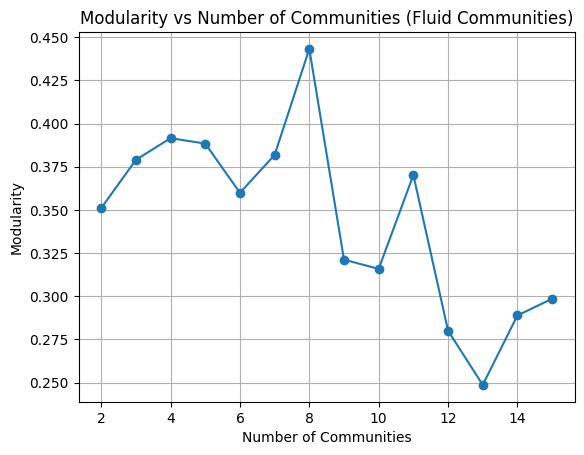

In [53]:
# List to store modularity values
modularity_fc = []

# Range of number of communities to consider
num_communities_range_fc = range(2, 16)

for k in num_communities_range_fc:
    # Compute the communities
    communities = list(nx.community.asyn_fluidc(G, k))
    
    # Calculate the modularity
    modularity = nx.community.modularity(G, communities)
    
    # Store the modularity
    modularity_fc.append(modularity)

# Plotting modularity vs number of communities
plt.plot(num_communities_range_fc, modularity_fc, marker='o')
plt.title('Modularity vs Number of Communities (Fluid Communities)')
plt.xlabel('Number of Communities')
plt.ylabel('Modularity')
plt.grid(True)
plt.show()

### Spectral Clustering

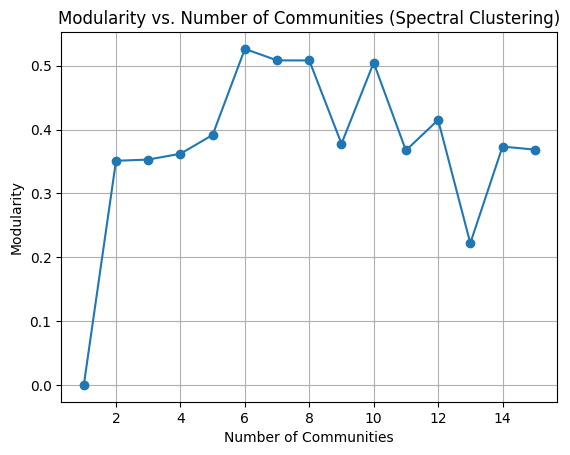

In [48]:
from sklearn.cluster import SpectralClustering
# List to store modularity values
modularity_sc = []

# Range of number of communities to consider
num_communities_range_sc = range(1, 16)
max_num_communities = 15

for num_communities in num_communities_range_sc:
    sc = SpectralClustering(num_communities, affinity='precomputed', random_state=42)
    labels = sc.fit_predict(A)
    partition = labels_to_partition(labels)
    mod = nx.community.modularity(G, partition)
    modularity_sc.append(mod)

# Plot modularity against the number of communities
plt.plot(num_communities_range_sc, modularity_sc, marker='o')
plt.xlabel('Number of Communities')
plt.ylabel('Modularity')
plt.title('Modularity vs. Number of Communities (Spectral Clustering)')
plt.grid(True)
plt.show()

### Girvan-Newman

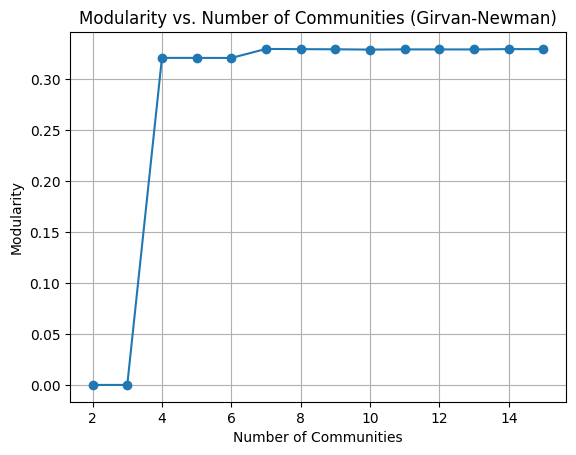

In [60]:
from networkx.algorithms.community import girvan_newman
from networkx.algorithms.community.quality import modularity
import itertools

# Run the Girvan-Newman algorithm
comp = girvan_newman(G)

# Initialize a dictionary to store modularity values
modularity_gn = []

# Calculate modularity for number of communities in the range
num_communities_range_gn = range(2, 16)
for i, communities in enumerate(itertools.islice(comp, 14)):
    num_communities = i + 2
    partition = tuple(sorted(c) for c in communities)
    mod = modularity(G, partition)
    modularity_gn.append(mod)

# Plot modularity against the number of communities for Girvan-Newman
plt.plot(num_communities_range_gn, modularity_gn, marker='o')
plt.xlabel('Number of Communities')
plt.ylabel('Modularity')
plt.title('Modularity vs. Number of Communities (Girvan-Newman)')
plt.grid(True)
plt.show()

### Plot all results together

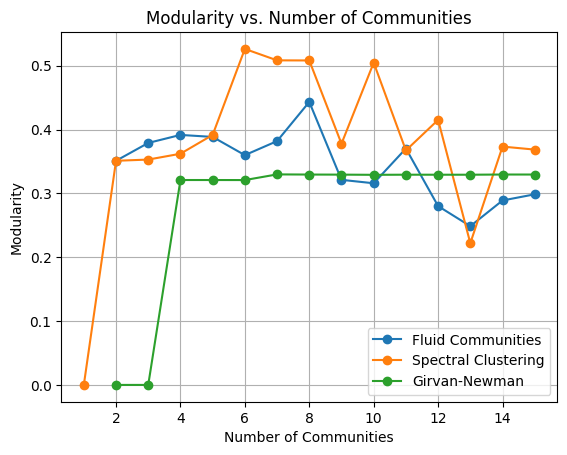

In [61]:
# Plotting modularity vs number of communities for all algorithms
plt.plot(num_communities_range_fc, modularity_fc, marker='o', label='Fluid Communities')
plt.plot(num_communities_range_sc, modularity_sc, marker='o', label='Spectral Clustering')
plt.plot(num_communities_range_gn, modularity_gn, marker='o', label='Girvan-Newman')
plt.xlabel('Number of Communities')
plt.ylabel('Modularity')
plt.title('Modularity vs. Number of Communities')
plt.legend()
plt.grid(True)
plt.show()